# Class Imbalance Analysis for Fraud Detection

This notebook studies the severe class imbalance in the fraud dataset and prepares a sampling strategy before model training.


In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

project_root = Path.cwd().resolve()
if not (project_root / "data" / "raw").exists():
    project_root = project_root.parent

df = pd.read_csv(project_root / "data" / "raw" / "PS_20174392719_1491204439457_log.csv")
print(f"Dataset shape: {df.shape}")
print(df["isFraud"].value_counts(normalize=True).to_dict())
print(df["type"].value_counts().to_dict())


Dataset shape: (6362620, 11)
{0: 0.9987091795518198, 1: 0.001290820448180152}
{'CASH_OUT': 2237500, 'PAYMENT': 2151495, 'CASH_IN': 1399284, 'TRANSFER': 532909, 'DEBIT': 41432}


Fraud transactions: 8213
Non-fraud transactions: 6354407
Imbalance ratio: 773.7:1


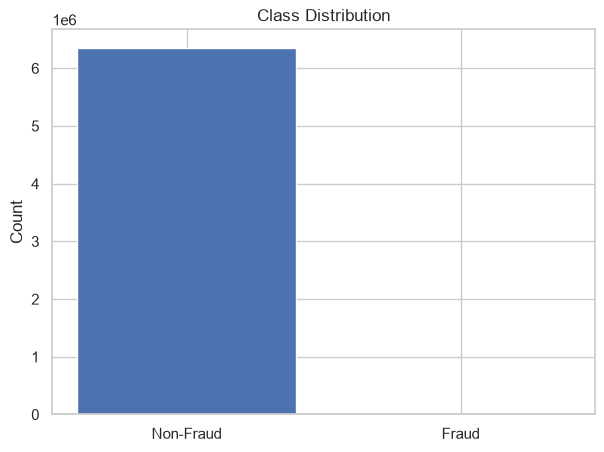

In [2]:
fraud_count = df["isFraud"].sum()
non_fraud_count = len(df) - fraud_count
print(f"Fraud transactions: {fraud_count}")
print(f"Non-fraud transactions: {non_fraud_count}")
print(f"Imbalance ratio: {non_fraud_count / fraud_count:.1f}:1")

sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(7, 5))
counts = df["isFraud"].value_counts().sort_index()
ax.bar(["Non-Fraud", "Fraud"], counts.values, color=["#4C72B0", "#C44E52"])
ax.set_title("Class Distribution")
ax.set_ylabel("Count")
plt.show()


In [3]:
fraud = df[df["isFraud"] == 1].copy()
non_fraud = df[df["isFraud"] == 0].copy()

sample_size = min(len(fraud) * 20, 250000)
non_fraud_sample = non_fraud.sample(n=sample_size, random_state=42)
balanced_df = pd.concat([fraud, non_fraud_sample], ignore_index=True)
balanced_df = balanced_df.sample(frac=1, random_state=42)

print(f"Sampled rows: {len(balanced_df)}")
print(balanced_df["isFraud"].value_counts(normalize=True).to_dict())

# Save sampled data for downstream modeling
out_path = project_root / "data" / "processed" / "fraud_sampled.csv"
out_path.parent.mkdir(parents=True, exist_ok=True)
balanced_df.to_csv(out_path, index=False)
print(f"Saved sampled dataset to: {out_path}")


Sampled rows: 172473
{0: 0.9523809523809523, 1: 0.047619047619047616}
Saved sampled dataset to: C:\Users\MY PC\Naresh IT\AI Projects store_fraud_detection\AI Projects store_fraud_detection\data\processed\fraud_sampled.csv


In [6]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix

feature_columns = [
    "amount",
    "oldbalanceOrg",
    "newbalanceOrig",
    "oldbalanceDest",
    "newbalanceDest",
    "type",
]

X = pd.get_dummies(
    balanced_df[feature_columns],
    columns=["type"],
    drop_first=True,
)
y = balanced_df["isFraud"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

model = LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42)
model.fit(X_train, y_train)

preds = model.predict(X_test)
print(classification_report(y_test, preds, target_names=["Non-Fraud", "Fraud"]))
print(confusion_matrix(y_test, preds))


              precision    recall  f1-score   support

   Non-Fraud       1.00      0.95      0.97     32852
       Fraud       0.47      0.92      0.63      1643

    accuracy                           0.95     34495
   macro avg       0.74      0.94      0.80     34495
weighted avg       0.97      0.95      0.96     34495

[[31175  1677]
 [  126  1517]]
